# RAG Assignment: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Corpus:** one 39-page PDF (`data/dpdp_corpus.pdf`) made of the *Digital Personal Data Protection Act, 2023*
(pages 1-21) and the *Digital Personal Data Protection Rules, 2025* (pages 22-39). See `data/SOURCES.md`.

**Both pipelines run over exactly the same chunks:**

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| Retrieve | Bi-encoder + cosine similarity, **top 10** | the same top 10 |
| Re-rank | none | Cross-encoder scores all 10 (query, chunk) pairs |
| Context for the LLM | top **3** by cosine | top **3** by cross-encoder score |
| Output | Answer 1 | Answer 2 (identical prompt) |

**Notebook map**

1. Setup and configuration
2. Load and clean the PDF, then chunk it
3. Bi-encoder index (FAISS) and baseline retrieval
4. Cross-encoder re-ranker
5. LLM answer generation (Gemini)
6. Running both pipelines side by side
7. Candidate stress-test queries: screening (retrieval only, no LLM cost)
8. Failure-mode analysis: rank shifts and Answer 1 vs. Answer 2
9. Latency profiling
10. Why not run the cross-encoder over the whole corpus?

**How to run:** create a virtual environment, `pip install -r requirements.txt`, put `GEMINI_API_KEY=...` in a
git-ignored `.env` file in the repo root (or type it when prompted), then run all cells from the repo root.

## 1. Setup and configuration

Everything that can be tuned lives in the configuration cell, so the experiment is easy to repeat.

In [1]:
import getpass
import hashlib
import json
import os
import re
import statistics
import time
from dataclasses import dataclass, replace
from pathlib import Path

import faiss
import numpy as np
import pandas as pd
import transformers
from dotenv import load_dotenv
from google import genai
from google.genai import errors as genai_errors
from google.genai import types as genai_types
from IPython.display import display
from pypdf import PdfReader
from sentence_transformers import CrossEncoder, SentenceTransformer

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")  # silences a harmless HF tokenizers warning
transformers.logging.set_verbosity_error()                  # keep the saved notebook free of model-loading noise
transformers.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

In [2]:
# ---- Corpus -------------------------------------------------------------------------------
PDF_PATH = Path("data/dpdp_corpus.pdf")
# (label, first_page, last_page), pages are 1-indexed inside the merged PDF
DOC_PARTS = [
    ("DPDP Act 2023", 1, 21),
    ("DPDP Rules 2025", 22, 39),
]

# ---- Chunking -----------------------------------------------------------------------------
CHUNK_WORDS = 120      # words per chunk (all-MiniLM-L6-v2 reads at most 256 word-pieces)
CHUNK_OVERLAP = 30     # words shared between neighbouring chunks, so clauses are not cut off sharply

# ---- Models -------------------------------------------------------------------------------
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"      # Pipeline 1 and candidate generation
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"     # Pipeline 2 re-ranker
# answer generation, same for both pipelines (gemini-2.5-flash is no longer offered to new API users)
GEMINI_MODEL = "gemini-3.7-flash"

# ---- Retrieval sizes ----------------------------------------------------------------------
TOP_K_RETRIEVE = 10    # candidates fetched by the bi-encoder
TOP_K_CONTEXT = 3      # chunks that are actually given to the LLM

In [3]:
# The key is read from a local, git-ignored .env file (never hard-code it in a public notebook).
load_dotenv(".env")
gemini = None   # created on the first uncached LLM call, so re-running with a warm cache needs no API key

## 2. Load, clean and chunk the PDF

The Gazette PDFs contain page furniture (running headers, page numbers, marginal cross-references such as
"24 of 1997.", Hindi header lines) that would only add noise to the embeddings, so it is stripped before chunking.

In [4]:
# Lines that are page furniture rather than law text.
NOISE_LINE_PATTERNS = [
    r".*THE GAZETTE OF INDIA.*",          # running header on every page
    r"^\[?PART II.*",                     # "[PART II-SEC. 3(i)]" or the broken "[PART II-"
    r"^SEC\. 1\]$",                       # running header of the Act pages
    r"^\d{1,2}$",                         # lone page numbers
    r"^\d+ of \d{4}\.$",                 # marginal cross-references such as "24 of 1997."
    r"^(UPLOADED BY|Uploaded by|and Published by|AND PUBLISHED BY|MGIPMRND|Digitally signed|Date: 20).*",
]
NOISE_RE = re.compile("|".join(f"(?:{p})" for p in NOISE_LINE_PATTERNS))
DEVANAGARI_RE = re.compile(r"[\u0900-\u097F]")      # the Rules PDF repeats a Hindi header on alternate pages
ACT_TITLE = "THE DIGITAL PERSONAL DATA PROTECTION ACT, 2023"


def clean_page_text(raw_text: str, page_no: int) -> str:
    """Strip page furniture from one page of extracted text and join it into a single line.

    Args:
        raw_text: Text of one PDF page as returned by pypdf.
        page_no: 1-indexed page number inside the merged PDF. Page 1 carries a block of
            registration/Hindi header text that is cut off just before the Act's title.

    Returns:
        The page's law text with headers, page numbers and cross-reference lines removed and
        hyphenation artefacts repaired.
    """
    if page_no == 1 and ACT_TITLE in raw_text:
        raw_text = raw_text[raw_text.index(ACT_TITLE):]
    kept = []
    for line in raw_text.splitlines():
        line = line.strip()
        if not line or DEVANAGARI_RE.search(line) or NOISE_RE.match(line):
            continue
        kept.append(line)
    text = " ".join(kept)
    # pypdf leaves stray spaces around hyphens at line breaks ("sub -section", "sub- section"); close them up.
    text = re.sub(r"(?<=\w) -(?=\w)", "-", text)
    text = re.sub(r"(?<=\w)- (?=[a-z])", "-", text)
    return text


def load_pages(pdf_path: Path, doc_parts: list[tuple[str, int, int]]) -> list[tuple[str, int, str]]:
    """Read the PDF and return cleaned text per page, tagged with the document it belongs to.

    Args:
        pdf_path: Path to the merged corpus PDF.
        doc_parts: (label, first_page, last_page) triples describing which pages belong to which document.

    Returns:
        A list of (document_label, page_no, cleaned_text) tuples in page order.
    """
    reader = PdfReader(str(pdf_path))
    pages = []
    for label, first, last in doc_parts:
        for page_no in range(first, last + 1):
            raw = reader.pages[page_no - 1].extract_text() or ""
            pages.append((label, page_no, clean_page_text(raw, page_no)))
    return pages


pages = load_pages(PDF_PATH, DOC_PARTS)
print(f"{len(pages)} pages, {sum(len(t.split()) for _, _, t in pages):,} words after cleaning")
print("\nSample (page 9):\n", pages[8][2][:600])

39 pages, 20,619 words after cleaning

Sample (page 9):
 (a) the volume and sensitivity of personal data processed; (b) risk to the rights of  Data Principal; (c) potential impact on the sovereignty and integrity of India; (d) risk to electoral democracy; (e) security of the State; and (f) public order. (2) The Significant Data Fiduciary shall— (a) appoint a Data Protection Officer who shall— (i) represent the Significant Data Fiduciary under the provisions of this Act; (ii) be based in India; (iii) be an individual responsible to the Board of Directors or similar governing body of the Significant Data Fiduciary; and (iv) be the point of contact for


In [5]:
@dataclass(frozen=True)
class Chunk:
    """One retrievable passage of the corpus."""

    chunk_id: int   # position in the global chunk list (also the row in the vector index)
    source: str     # which document it comes from (Act or Rules)
    page: int       # page of the merged PDF on which the chunk starts
    text: str


def build_chunks(pages: list[tuple[str, int, str]], chunk_words: int, overlap: int) -> list[Chunk]:
    """Split the corpus into overlapping fixed-size word windows.

    Windows never cross from the Act into the Rules; each document is chunked on its own. Every word
    remembers its page so a chunk can report the page where it starts.

    Args:
        pages: Output of load_pages.
        chunk_words: Number of words per window.
        overlap: Number of words that consecutive windows share.

    Returns:
        The list of chunks, numbered consecutively from 0.
    """
    step = chunk_words - overlap
    chunks: list[Chunk] = []
    for source in dict.fromkeys(src for src, _, _ in pages):          # documents in order, without repeats
        words = [(w, page) for src, page, text in pages if src == source for w in text.split()]
        for start in range(0, len(words), step):
            window = words[start:start + chunk_words]
            if start > 0 and len(window) <= overlap:                  # tail already covered by the previous chunk
                break
            chunks.append(Chunk(len(chunks), source, window[0][1], " ".join(w for w, _ in window)))
    return chunks


chunks = build_chunks(pages, CHUNK_WORDS, CHUNK_OVERLAP)
print(f"{len(chunks)} chunks "
      f"({sum(c.source == 'DPDP Act 2023' for c in chunks)} from the Act, "
      f"{sum(c.source == 'DPDP Rules 2025' for c in chunks)} from the Rules)")
print(f"\nExample chunk #40 (page {chunks[40].page}, {chunks[40].source}):\n{chunks[40].text}")

230 chunks (117 from the Act, 113 from the Rules)

Example chunk #40 (page 8, DPDP Act 2023):
(8) The purpose referred to in clause (a) of sub-section (7) shall be deemed to no longer be served, if the Data Principal does not– – (a) approach the Data Fiduciary for the performance of the specified purpose; and (b) exercise any of her rights in relation to such processing, for such time period as may be prescribed, and different time periods may be prescribed for different classes of Data Fiduciaries and for different purposes. (9) A Data Fiduciary shall publish, in such manner as may be prescribed, the business contact information of a Data Protection Officer, if applicable, or a person who is able to answer on behalf of the Data Fiduciary, the questions, if any, raised by the


## 3. Bi-encoder index and baseline retrieval

A **bi-encoder** embeds the query and every chunk *independently*. Chunk vectors are computed once and stored;
at query time only the query is embedded and compared with the stored vectors. The vectors are L2-normalised,
so the inner product that FAISS computes (`IndexFlatIP`) is exactly the cosine similarity.

In [6]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device="cpu")

# One-off cost: embed every chunk. normalize_embeddings=True makes inner product == cosine similarity.
chunk_vectors = bi_encoder.encode(
    [c.text for c in chunks], batch_size=32, normalize_embeddings=True,
    convert_to_numpy=True, show_progress_bar=False,
).astype("float32")

index = faiss.IndexFlatIP(chunk_vectors.shape[1])   # exact (brute-force) inner-product search
index.add(chunk_vectors)
print(f"Indexed {index.ntotal} vectors of dimension {chunk_vectors.shape[1]}")

# Sanity check: how many chunks are longer than the encoder can read (the rest would be silently truncated)?
token_counts = [len(bi_encoder.tokenizer.tokenize(c.text)) for c in chunks]
too_long = sum(n > bi_encoder.max_seq_length for n in token_counts)
print(f"Encoder limit: {bi_encoder.max_seq_length} word-pieces | longest chunk: {max(token_counts)} | "
      f"chunks over the limit: {too_long}")

Indexed 230 vectors of dimension 384
Encoder limit: 256 word-pieces | longest chunk: 242 | chunks over the limit: 0


In [7]:
@dataclass(frozen=True)
class Hit:
    """A retrieved chunk together with its rank and score in each retrieval stage."""

    chunk_id: int
    bi_rank: int                 # 1 = best according to cosine similarity
    bi_score: float              # cosine similarity
    ce_rank: int | None = None   # filled in after re-ranking
    ce_score: float | None = None  # cross-encoder logit (higher = more relevant, not a probability)


def retrieve(query: str, k: int = TOP_K_RETRIEVE) -> tuple[list[Hit], dict[str, float]]:
    """Pipeline 1, steps a-b: embed the query and fetch the k nearest chunks by cosine similarity.

    Args:
        query: The user question.
        k: Number of candidates to return.

    Returns:
        A tuple (hits, timings). hits are ordered best-first with bi_rank 1..k; timings holds the seconds
        spent on query embedding ("embed_s") and on the vector search ("search_s").
    """
    t0 = time.perf_counter()
    query_vector = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    t1 = time.perf_counter()
    scores, ids = index.search(query_vector, k)
    t2 = time.perf_counter()
    hits = [Hit(int(cid), rank, float(score)) for rank, (cid, score) in enumerate(zip(ids[0], scores[0]), start=1)]
    return hits, {"embed_s": t1 - t0, "search_s": t2 - t1}


def show_chunks(hits: list[Hit], n: int = 3, width: int = 160) -> None:
    """Print the first n hits with their page and a text preview (quick visual inspection helper)."""
    for h in hits[:n]:
        c = chunks[h.chunk_id]
        print(f"#{h.bi_rank} chunk {c.chunk_id} | {c.source} p.{c.page} | cos={h.bi_score:.3f} | {c.text[:width]}...")


demo_hits, _ = retrieve("When can personal data be processed without consent?")
show_chunks(demo_hits, n=3)

#1 chunk 16 | DPDP Act 2023 p.4 | cos=0.724 | as soon as it is reasonably practicable, give to the Data Principal a notice informing her,–– (i) the personal data and the purpose for which the same has been ...
#2 chunk 17 | DPDP Act 2023 p.5 | cos=0.698 | until and unless the Data Principal withdraws her consent. Illustration. X, an individual, gave her consent to the processing of her personal data for an online...
#3 chunk 137 | DPDP Rules 2025 p.25 | cos=0.666 | any law for the time being in force, or, for the corresponding time period specified in the Third Schedule, if the Data Principal neither approaches such Data F...


## 4. Cross-encoder re-ranker

A **cross-encoder** reads the query and one chunk *together* in a single transformer pass, so every query token can
attend to every chunk token. That joint attention can see things independent embeddings cannot (for example
a "not" or "except"), but nothing can be pre-computed: each (query, chunk) pair needs its own forward pass.

In [8]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, max_length=512, device="cpu")


def rerank(query: str, hits: list[Hit]) -> tuple[list[Hit], float]:
    """Pipeline 2, steps b-c: score every (query, chunk) pair with the cross-encoder and re-sort.

    Args:
        query: The user question.
        hits: The candidates returned by retrieve (the same top 10 that Pipeline 1 saw).

    Returns:
        A tuple (reranked, seconds). reranked contains copies of all hits, ordered by descending
        cross-encoder score, with ce_rank and ce_score filled in. The bi_rank of each hit is preserved so
        rank shifts can be read off directly.
    """
    pairs = [(query, chunks[h.chunk_id].text) for h in hits]
    t0 = time.perf_counter()
    scores = cross_encoder.predict(pairs, batch_size=len(pairs), show_progress_bar=False)
    elapsed = time.perf_counter() - t0
    order = np.argsort(-scores)                       # indices of hits, best cross-encoder score first
    reranked = [replace(hits[i], ce_rank=rank, ce_score=float(scores[i])) for rank, i in enumerate(order, start=1)]
    return reranked, elapsed


demo_reranked, _ = rerank("When can personal data be processed without consent?", demo_hits)
print("Top 3 after re-ranking:")
for h in demo_reranked[:3]:
    print(f"  chunk {h.chunk_id}: bi-encoder rank {h.bi_rank} -> cross-encoder rank {h.ce_rank} (score {h.ce_score:.2f})")

Top 3 after re-ranking:
  chunk 24: bi-encoder rank 7 -> cross-encoder rank 1 (score 6.13)
  chunk 16: bi-encoder rank 1 -> cross-encoder rank 2 (score 4.40)
  chunk 17: bi-encoder rank 2 -> cross-encoder rank 3 (score 4.19)


## 5. Answer generation (Gemini)

Both pipelines call the **same function with the same prompt template**; only the three chunks passed in differ.
The prompt tells the model to use only the excerpts and to say so when they are insufficient, because this Act is
public and the model could otherwise answer from memory and hide a retrieval failure. `temperature=0` and
thinking disabled keep the two answers comparable. Answers are cached in `results/llm_cache.json` (the free API tier
only allows about 20 requests per day and model), so re-running the notebook does not call the API again.

In [9]:
SYSTEM_PROMPT = (
    "You answer questions about India's Digital Personal Data Protection Act, 2023 and the Digital Personal "
    "Data Protection Rules, 2025. Use ONLY the numbered excerpts provided; do not rely on outside knowledge. "
    "If the excerpts do not contain enough information to answer fully, say clearly what is missing instead of "
    "guessing. Cite the excerpts you used like [1] or [2]. Keep the answer under 120 words."
)


def build_prompt(question: str, context_chunks: list[Chunk]) -> str:
    """Format the question and the retrieved chunks into the user message (identical for both pipelines).

    Args:
        question: The user question.
        context_chunks: The chunks to show to the model, best first.

    Returns:
        The user message: numbered excerpts followed by the question.
    """
    excerpts = "\n\n".join(f"[{i}] ({c.source}, p.{c.page}) {c.text}" for i, c in enumerate(context_chunks, start=1))
    return f"Excerpts:\n\n{excerpts}\n\nQuestion: {question}"


# Free-tier Gemini keys allow only ~20 requests per day and model, so every answer is cached on disk
# (keyed by model + prompts). Re-running the notebook costs nothing; delete the file to regenerate.
CACHE_PATH = Path("results/llm_cache.json")
llm_cache: dict[str, dict] = json.loads(CACHE_PATH.read_text()) if CACHE_PATH.exists() else {}


def get_gemini_client() -> genai.Client:
    """Create the Gemini client on first use, asking for the key only if it is not in the environment."""
    global gemini
    if gemini is None:
        gemini = genai.Client(api_key=os.environ.get("GEMINI_API_KEY") or getpass.getpass("Gemini API key (not saved): "))
    return gemini


def generate_answer(question: str, context_chunks: list[Chunk], max_retries: int = 5) -> dict:
    """Ask Gemini to answer the question from the given chunks (cached, retrying on transient errors).

    Args:
        question: The user question.
        context_chunks: The chunks to show to the model.
        max_retries: How many times to retry on HTTP 429/5xx before giving up.

    Returns:
        A dict with the answer "text", wall-clock "seconds" of the original API call and the token counts
        "prompt_tokens" and "output_tokens". Cached answers return the numbers of the original call.

    Raises:
        genai_errors.APIError: On non-retryable errors, or when the daily free-tier quota is exhausted.
    """
    prompt = build_prompt(question, context_chunks)
    cache_key = hashlib.sha256(f"{GEMINI_MODEL}\n{SYSTEM_PROMPT}\n{prompt}".encode()).hexdigest()
    if cache_key in llm_cache:
        return llm_cache[cache_key]

    config = genai_types.GenerateContentConfig(
        system_instruction=SYSTEM_PROMPT,
        temperature=0.0,
        max_output_tokens=800,
        thinking_config=genai_types.ThinkingConfig(thinking_budget=0),   # no hidden reasoning: faster, more repeatable
    )
    for attempt in range(max_retries + 1):
        t0 = time.perf_counter()
        try:
            response = get_gemini_client().models.generate_content(model=GEMINI_MODEL, contents=prompt, config=config)
            usage = response.usage_metadata
            result = {
                "text": (response.text or "").strip(),
                "seconds": time.perf_counter() - t0,
                "prompt_tokens": usage.prompt_token_count,
                "output_tokens": usage.candidates_token_count,
            }
            llm_cache[cache_key] = result
            CACHE_PATH.parent.mkdir(exist_ok=True)
            CACHE_PATH.write_text(json.dumps(llm_cache, indent=1))
            return result
        except genai_errors.APIError as err:
            daily_quota_hit = err.code == 429 and "PerDay" in str(err)    # waiting a few seconds cannot fix this
            if err.code not in (429, 500, 503, 504) or daily_quota_hit or attempt == max_retries:
                raise
            time.sleep(5 * 2 ** attempt)                                  # exponential backoff: 5s, 10s, 20s, ...

## 6. Running both pipelines side by side

`compare_pipelines` retrieves the top 10 **once**, so Pipeline 2 re-ranks exactly the candidates Pipeline 1 saw.

In [10]:
@dataclass
class Comparison:
    """Everything produced by running one query through both pipelines."""

    query: str
    baseline_hits: list[Hit]      # top 10 by cosine similarity (bi_rank 1..10)
    reranked_hits: list[Hit]      # the same 10, ordered by cross-encoder score
    answer_1: dict | None         # Pipeline 1 answer (None when the LLM was skipped)
    answer_2: dict | None         # Pipeline 2 answer
    timings: dict                 # seconds per stage for this single run

    @property
    def context_1(self) -> list[int]:
        """Chunk ids given to the LLM by Pipeline 1 (top 3 by cosine)."""
        return [h.chunk_id for h in self.baseline_hits[:TOP_K_CONTEXT]]

    @property
    def context_2(self) -> list[int]:
        """Chunk ids given to the LLM by Pipeline 2 (top 3 by cross-encoder)."""
        return [h.chunk_id for h in self.reranked_hits[:TOP_K_CONTEXT]]


def compare_pipelines(query: str, with_llm: bool = True) -> Comparison:
    """Run one query through Pipeline 1 and Pipeline 2.

    Args:
        query: The user question.
        with_llm: If False, stop after retrieval/re-ranking and skip the two Gemini calls.

    Returns:
        A Comparison with both rankings, both answers (if requested) and per-stage timings.
    """
    hits, t_ret = retrieve(query)                      # shared by both pipelines
    reranked, t_rerank = rerank(query, hits)           # Pipeline 2 only
    answer_1 = answer_2 = None
    if with_llm:
        answer_1 = generate_answer(query, [chunks[h.chunk_id] for h in hits[:TOP_K_CONTEXT]])
        answer_2 = generate_answer(query, [chunks[h.chunk_id] for h in reranked[:TOP_K_CONTEXT]])
    timings = {**t_ret, "rerank_s": t_rerank}
    return Comparison(query, hits, reranked, answer_1, answer_2, timings)


def candidates_table(cmp: Comparison, gold_ids: set[int] | None = None) -> pd.DataFrame:
    """Tabulate the 10 candidates with their rank in each stage (rank shift = bi_rank - ce_rank).

    Args:
        cmp: A Comparison returned by compare_pipelines.
        gold_ids: Chunk ids known to contain the answer; they are flagged in the "gold" column.

    Returns:
        A DataFrame ordered by the bi-encoder rank.
    """
    gold_ids = gold_ids or set()
    rows = []
    for h in sorted(cmp.reranked_hits, key=lambda x: x.bi_rank):
        c = chunks[h.chunk_id]
        rows.append({
            "bi_rank": h.bi_rank, "ce_rank": h.ce_rank, "shift": h.bi_rank - h.ce_rank,
            "chunk": h.chunk_id, "page": c.page, "cos": round(h.bi_score, 3), "ce_score": round(h.ce_score, 2),
            "gold": "GOLD" if h.chunk_id in gold_ids else "",
            "in_ctx_1": h.chunk_id in cmp.context_1, "in_ctx_2": h.chunk_id in cmp.context_2,
            "text": c.text[:100] + "...",
        })
    return pd.DataFrame(rows)

## 7. Candidate stress-test queries (screening, retrieval only)

Each candidate query comes with a **gold anchor**: a short phrase that appears only in the clause that really
answers the question. The chunk(s) containing that phrase are the *gold chunks*, so rank shifts are measured
automatically instead of by eye. Screening makes no LLM calls: it records where the gold chunk lands in the
bi-encoder's top 10 and where it lands after re-ranking.

The candidates were written to provoke the failure types in the brief:

* **NEGATION**: the answer hinges on "shall not" / "not entitled to";
* **EXCEPTION**: a general rule exists somewhere and the answer is a carve-out elsewhere;
* **DISTRACTOR**: a topically similar chunk shares the query's keywords but the answer is in a different chunk.

All remaining candidates are listed here, including those that did **not** show a failure, so the screening is a stress test
and not a cherry-picked benchmark. Because the cross-encoder only reorders the top 10, re-ranking can fix a query
only if the gold chunk is already among the 10 candidates.

**Removed from the pool (5 queries about the penalty Schedule).** The PDF text extraction flattens the Schedule table:
the row labels and the penalty amounts come out as two separate lists that are split across neighbouring chunks, so
no single chunk says "this breach, that amount" and a fair gold chunk cannot be defined. These were removed before
scoring, whatever their outcome:

* What is the maximum penalty for a breach of the duties of a Data Principal?
* What penalty applies if a company fails to protect personal data with security safeguards?
* What is the penalty for breaking the rules on children's personal data?
* What is the fine for failing to tell the Board about a personal data breach?
* What is the penalty if someone files a false complaint?

In [11]:
def normalise(text: str) -> str:
    """Lower-case and collapse whitespace so anchors match regardless of line breaks in the PDF."""
    return re.sub(r"\s+", " ", text).lower()


def find_gold_chunks(anchor: str) -> set[int]:
    """Return the ids of all chunks whose text contains the anchor phrase.

    Because neighbouring chunks overlap, an anchor near a chunk boundary can appear in two chunks.
    """
    needle = normalise(anchor)
    return {c.chunk_id for c in chunks if needle in normalise(c.text)}


def best_rank(ranked_chunk_ids: list[int], gold_ids: set[int]) -> int | None:
    """1-based position of the best-placed gold chunk in a ranked list, or None if no gold chunk is in it."""
    positions = [pos for pos, cid in enumerate(ranked_chunk_ids, start=1) if cid in gold_ids]
    return min(positions) if positions else None


def classify_outcome(base_rank: int | None, ce_rank: int | None) -> str:
    """Label what re-ranking did to the gold chunk relative to the top-3 cut-off given to the LLM."""
    if base_rank is None:
        return "GOLD NOT IN TOP-10"            # a retrieval (recall) failure: re-ranking cannot repair it
    if base_rank <= TOP_K_CONTEXT:
        return "ALREADY TOP-3" if ce_rank <= TOP_K_CONTEXT else "WORSE"
    return "FIXED" if ce_rank <= TOP_K_CONTEXT else "STILL OUTSIDE TOP-3"


def screen_case(case: dict) -> dict:
    """Run retrieval and re-ranking (no LLM) for one candidate query and summarise the gold chunk's movement.

    Args:
        case: A dict with the keys id, category, query and gold (set of gold chunk ids).

    Returns:
        One row for the screening table: ranks before/after re-ranking, the gold chunk's rank among ALL chunks
        and the outcome label.
    """
    cmp = compare_pipelines(case["query"], with_llm=False)
    base_rank = best_rank([h.chunk_id for h in cmp.baseline_hits], case["gold"])
    ce_rank = best_rank([h.chunk_id for h in cmp.reranked_hits], case["gold"])

    # Rank among all chunks tells us how far outside the top 10 a missed gold chunk was.
    q_vec = bi_encoder.encode([case["query"]], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    _, all_ids = index.search(q_vec, index.ntotal)
    rank_all = best_rank([int(i) for i in all_ids[0]], case["gold"])

    return {"id": case["id"], "category": case["category"], "query": case["query"],
            "gold_chunks": sorted(case["gold"]), "rank_among_all_chunks": rank_all,
            "baseline_rank": base_rank, "reranked_rank": ce_rank,
            "outcome": classify_outcome(base_rank, ce_rank)}

In [12]:
NEGATION_CASES = [  # (query, gold anchor)
    ('Can a Consent Manager outsource its work to another company?',
     'shall not sub-contract or assign'),
    ("Can the Board take a company's equipment into custody during an inquiry?",
     'take into custody any equipment'),
    ('Do Members of the Data Protection Board receive a pension?',
     'shall not be entitled to payment of pension or gratuity'),
    ('Can the Chairperson of the Board be removed without being heard?',
     'shall not be removed from her office by the Central Government unless'),
    ('Can a former Board Member immediately take a job with a company that she investigated?',
     'shall not, for a period of one year from the date on which they cease to hold such office'),
    ('Can a Consent Manager read the personal data that passes through its platform?',
     'contents thereof are not readable by it'),
    ('Is a company allowed to show targeted advertising to children?',
     'targeted advertising directed at children'),
    ('Can a civil court hear a dispute that the Board is empowered to decide?',
     'No civil court shall have the jurisdiction'),
    ('Is the Appellate Tribunal bound to follow the Code of Civil Procedure?',
     'shall not be bound by the procedure laid down by the Code of Civil Procedure'),
    ('Are Board Members paid a sitting fee for attending meetings?',
     'shall not be entitled to any sitting fee'),
    ('Can a Board Member vote on a matter in which she has a personal interest?',
     'she shall not participate in or vote on the same'),
]

In [13]:
EXCEPTION_CASES = [  # (query, gold anchor)
    ('Can an email service create an account for a child without parental consent?',
     'creation of a user account for communicating by email'),
    ('Is a school transport operator allowed to track the location of the children it carries?',
     'tracking the location of such children'),
    ('Can a Significant Data Fiduciary send personal data abroad?',
     'not transferred outside the territory of India'),
    ('If personal data is processed to enforce a legal claim, which duties of the Data Fiduciary still apply?',
     'except sub-sections (1) and (5) of section 8'),
    ('Does the Act apply to personal data that someone posts publicly on social media?',
     'made or caused to be made publicly available'),
    ('Does the Act apply to data processed for research?',
     'necessary for research, archiving or statistical purposes'),
    ('Can personal data be processed without consent during a disaster?',
     'any breakdown of public order'),
    ("Can an employer use an employee's personal data without asking for consent?",
     'prevention of corporate espionage'),
    ("Can a hospital process a child's data without a parent's consent?",
     'mental health establishment or healthcare professional'),
    ("Must a bank delete a customer's data when the account is closed?",
     'maintain the record of the identity of its clients for a period of ten years'),
    ('Which obligations can the government waive for startups?',
     'including startups'),
    ("Does a company have to keep a user's data only until the purpose is served even if the government is the one processing it?",
     'In respect of processing by the State or any instrumentality of the State'),
    ('Are there countries to which personal data cannot be sent?',
     'restrict the transfer of personal data by a Data Fiduciary for processing to such country'),
    ('If a user withdraws consent, can the company still process data for goods she already paid for?',
     'may not stop the processing for supply of the goods already ordered and paid for'),
    ('Does an e-commerce platform have to keep order data even if the user deletes her account?',
     'even if X deletes her account'),
    ('Can the Board extend the time limit for completing an inquiry?',
     'not exceeding three months at a time'),
    ('Will the Appellate Tribunal accept an appeal filed after the deadline?',
     'sufficient cause for not preferring the appeal'),
    ('Must a company tell a user which other companies received her data if the sharing was for crime investigation?',
     'for the purpose of prevention or detection or investigation of offences or cyber incidents'),
    ('Does the Act cover a company located outside India?',
     'outside the territory of India, if such processing is in connection with'),
    ('Does the Act apply to an Indian outsourcing firm processing the data of foreign customers?',
     'personal data of Data Principals not within the territory of India is processed pursuant to any contract'),
    ("Can a lender use a defaulter's personal data without consent?",
     'ascertaining the financial information and assets and liabilities'),
    ('Is a seller on an online marketplace treated as an e-commerce entity for data erasure timelines?',
     'but does not include a seller offering her goods or services for sale on a marketplace'),
    ('Is personal data used for private household purposes covered by the Act?',
     'for any personal or domestic purpose'),
    ('Can a company get more time than 72 hours to give the Board details of a breach?',
     'within such longer period as the Board may allow on a request made in writing'),
    ('Can the Government stop a company from telling a user that her data was requested?',
     'not disclose such furnishing to affected Data Principal'),
    ('Which kinds of Data Fiduciaries are exempt from the ban on tracking children?',
     'Classes of Data Fiduciaries in respect of whom provisions of sub-sections (1) and (3) of section 9 shall'),
    ("For what purposes can a child's data be processed without verifiable parental consent?",
     'Purposes for which provisions of sub-sections (1) and (3) of section 9 shall not apply'),
    ('Can a school monitor the behaviour of its students?',
     'tracking and behavioural monitoring'),
    ('Does the ban on tracking children apply to a crèche?',
     'in whose care infants and children in a crèche'),
    ('Which State bodies are completely exempt from the Act?',
     'by such instrumentality of the State as the Central Government may notify'),
    ('For how long can the Government exempt a company from the Act?',
     'before expiry of five years from the date of commencement of this Act'),
    ('Are there any purposes for which the three-year erasure period does not apply?',
     'For all purposes, except for the following'),
    ('Can the Government be sued for something it did in good faith under the Act?',
     'for anything which is done or intended to be done in good faith'),
    ('Can personal data be used without consent in a medical emergency?',
     'responding to a medical emergency involving a threat to the life'),
    ('Can data be processed without consent during an epidemic?',
     'during an epidemic, outbreak of disease'),
    ('Can a company use personal data to comply with a court order from another country?',
     'claims of a contractual or civil nature under any law for the time being in force outside India'),
    ('Can a person be forced to share personal data held by a bank with the government?',
     'for fulfilling any obligation under any law for the time being in force in India on any person to disclose'),
    ("Are research bodies free from the Act's rules?",
     'standards specified in Second Schedule'),
    ('Does the right to correct data apply to data the State processes for a decision-free purpose?',
     'where such processing is for a purpose that does not include making of a decision'),
    ('Does the ban on tracking children have any exceptions?',
     'as are specified in Part A of Fourth Schedule, subject to such conditions'),
    ("Are some companies allowed to process children's data without getting parental consent?",
     'as are specified in Part A of Fourth Schedule, subject to such conditions'),
    ("Does a doctor need a parent's consent before processing a child's health data?",
     'to the extent necessary for the protection of her health'),
    ("Is a healthcare provider exempt from parental consent for children's data?",
     'to the extent necessary for the protection of her health'),
    ('Can a company keep personal data after the user withdraws consent?',
     'unless retention is necessary for compliance with any law for the time being in force'),
    ("Can a company refuse a user's request to erase her data?",
     'unless retention of the same is necessary for the specified purpose'),
    ('Does the government have to delete personal data once its purpose is over?',
     'In respect of processing by the State or any instrumentality of the State'),
    ('Are national security agencies covered by the Act?',
     'by such instrumentality of the State as the Central Government may notify'),
    ('Can a person go straight to the Board without first complaining to the company?',
     'shall exhaust the opportunity of redressing her grievance'),
    ('Can the government raise the penalty amounts in the Schedule?',
     'increasing any penalty specified therein to more than twice'),
    ("When can the government order a company's services to be blocked?",
     'in two or more instances'),
    ('When may a company send personal data abroad?',
     'subject to the restriction that the Data Fiduciary shall meet such requirements'),
    ('Can another law restrict sending personal data abroad even if the government has not?',
     'provides for a higher degree of protection for or restriction on transfer'),
    ('What happens if this Act conflicts with another law?',
     'shall prevail to the extent of such conflict'),
    ("Can a company track a child's real-time location?",
     'determination of real-time location of a child'),
    ('Can a company process personal data to check that a user is not a child?',
     'confirmation by the Data Fiduciary that the Data Principal is not a child'),
    ('Does old consent given before the law took effect remain valid?',
     'before the date of commencement of this Act'),
    ("Is a user's data erased even if she regularly logs into her account?",
     'unless she logs into her user account or otherwise initiates contact'),
    ("Which online gaming companies must erase inactive users' data?",
     'fifty lakh registered users'),
    ('Can an employer process employee data to protect trade secrets without consent?',
     'maintenance of confidentiality of trade secrets'),
    ('Can personal data be processed without consent to obey a court order?',
     'for compliance with any judgment or decree or order issued under any law'),
    ('Can data be processed without consent to help people during a disaster?',
     'during any disaster, or any breakdown of public order'),
    ("Can a bank keep a customer's records for ten years after closing the account?",
     'maintain the record of the identity of its clients for a period of ten years'),
    ("Can a court or tribunal process personal data without following the Act's duties?",
     'by any court or tribunal or any other body'),
    ('Does the Act apply to data processed to detect or investigate a crime?',
     'prevention, detection, investigation or prosecution of any offence or contravention'),
    ('Can a company merge with another and share personal data without consent?',
     'scheme of compromise or arrangement or merger or amalgamation'),
    ('Can a person nominate someone to exercise her rights if she dies?',
     'in the event of death or incapacity of the Data Principal'),
    ('Must the Consent Manager be controlled by the same people forever?',
     'shall not be transferred by way of sale, merger or otherwise'),
    ('Can the Board use equipment seized from a company?',
     'adversely affect the day-to-day functioning of a person'),
    ('Can the Board act against a person who gave a voluntary undertaking?',
     'constitute a bar on proceedings under the provisions of this Act'),
    ('Can the Board punish someone who files a false complaint?',
     'false or frivolous, it may issue a warning or impose costs on the complainant'),
    ("Is the Appellate Tribunal's order executable like a court decree?",
     'executable by it as a decree of civil court'),
    ('Can the Government ask for information from a company without the company telling the user?',
     'to not disclose such furnishing to affected Data Principal'),
    ('May a Data Principal be a minor whose parent acts for her?',
     'includes the parents or lawful guardian of such a child'),
]

In [14]:
DISTRACTOR_CASES = [  # (query, gold anchor)
    ('How quickly must a company report a data breach to the Board?',
     'within seventy-two hours'),
    ('How many days does a company have to respond to a grievance from a user?',
     'not exceeding ninety days'),
    ('How much net worth does a Consent Manager need to register?',
     'net worth of the applicant is not less than two crore rupees'),
    ('How long must a Consent Manager keep its records of consents?',
     'for at least seven years'),
    ('What is the monthly salary of the Chairperson of the Board?',
     'four lakh fifty thousand per month'),
    ('How long does the Board have to finish an inquiry?',
     'completed within a period of six months from the date of receipt'),
    ('What is the quorum for a meeting of the Board?',
     'One-third of the membership of the Board shall be the quorum'),
    ('How many days does a person have to appeal against an order of the Board?',
     'within a period of sixty days from the date of receipt'),
    ("How much notice must a company give before erasing an inactive user's data?",
     'At least forty-eight hours before completion'),
    ('At what age does a person stop being a child under the Act?',
     'not completed the age of eighteen years'),
    ('For how long must logs be kept to detect unauthorised access?',
     'retain such logs and personal data for a period of one year'),
    ('How long is the term of office of the Chairperson of the Board?',
     'hold office for a term of two years'),
    ('Where must the Data Protection Officer of a Significant Data Fiduciary be located?',
     'be based in India'),
    ('How often must a Significant Data Fiduciary carry out an impact assessment?',
     'once in every period of twelve months'),
    ('How much is the penalty for breaking a voluntary undertaking given to the Board?',
     'Breach of any term of voluntary undertaking accepted by the Board under section 32'),
    ('Where does the money collected from penalties go?',
     'credited to the Consolidated Fund of India'),
    ('How is the fee for an appeal to the Appellate Tribunal paid?',
     'Unified Payments Interface'),
    ('Who selects the Chairperson of the Board?',
     'with the Cabinet Secretary as the chairperson'),
    ('Who is the Data Protection Officer of a Significant Data Fiduciary answerable to?',
     'responsible to the Board of Directors or similar governing body'),
    ('Can a company escape responsibility by blaming its Data Processor?',
     'irrespective of any agreement to the contrary'),
    ('Is a written contract needed to hire a Data Processor?',
     'only under a valid contract'),
    ("What happens if Board Members' votes are tied?",
     'second or casting vote'),
    ('Can the Chairperson act alone in an emergency?',
     'emergent situation warrants immediate action'),
    ('In which languages must a notice be available to the user?',
     'English or any language specified in the Eighth Schedule'),
    ('How many years can a Board officer be on deputation?',
     'for a period not exceeding five years'),
    ('What is the minimum shareholding that a Consent Manager must disclose?',
     'in excess of two per cent'),
    ('Who can be disqualified from being a Board Member?',
     'has been adjudged as an insolvent'),
    ('What identity details can prove a parent is an adult?',
     'virtual token mapped to such details, which is issued by an authorised entity'),
]

In [15]:
# Number the candidates (NEG-01, EXC-01, DIS-01, ...) and resolve each anchor to its gold chunk(s).
QUERY_CASES = []
for category, prefix, items in [("NEGATION", "NEG", NEGATION_CASES),
                                ("EXCEPTION", "EXC", EXCEPTION_CASES),
                                ("DISTRACTOR", "DIS", DISTRACTOR_CASES)]:
    for n, (query, anchor) in enumerate(items, start=1):
        gold = find_gold_chunks(anchor)
        assert gold, f"Anchor for {prefix}-{n:02d} matches no chunk - check the phrase against the cleaned text"
        QUERY_CASES.append(dict(id=f"{prefix}-{n:02d}", category=category, query=query, anchor=anchor, gold=gold))
CASES_BY_ID = {c["id"]: c for c in QUERY_CASES}

screen_df = pd.DataFrame([screen_case(c) for c in QUERY_CASES])
Path("results").mkdir(exist_ok=True)
screen_df.to_csv("results/screening_results.csv", index=False)       # full table is kept in the repo
print(f"{len(screen_df)} candidate queries scored")
pd.crosstab(screen_df["category"], screen_df["outcome"], margins=True)

112 candidate queries scored


outcome,ALREADY TOP-3,FIXED,GOLD NOT IN TOP-10,STILL OUTSIDE TOP-3,WORSE,All
category,,,,,,
DISTRACTOR,20,5,2,1,0,28
EXCEPTION,30,4,30,7,2,73
NEGATION,5,2,2,1,1,11
All,55,11,34,9,3,112


In [16]:
# Queries where re-ranking changed the picture. The full table is in results/screening_results.csv.
interesting = screen_df[screen_df["outcome"].isin(["FIXED", "WORSE", "STILL OUTSIDE TOP-3"])]
interesting.sort_values(["outcome", "category", "id"]).reset_index(drop=True)

,id,category,query,gold_chunks,rank_among_all_chunks,baseline_rank,reranked_rank,outcome
0,DIS-05,DISTRACTOR,What is the monthly salary of the Chairperson of the Board?,[208],6,6.0,2.0,FIXED
1,DIS-13,DISTRACTOR,Where must the Data Protection Officer of a Significant Data Fiduciary be located?,"[45, 46]",4,4.0,2.0,FIXED
2,DIS-15,DISTRACTOR,How much is the penalty for breaking a voluntary undertaking given to the Board?,[115],7,7.0,1.0,FIXED
3,DIS-18,DISTRACTOR,Who selects the Chairperson of the Board?,"[162, 163]",9,9.0,3.0,FIXED
4,DIS-19,DISTRACTOR,Who is the Data Protection Officer of a Significant Data Fiduciary answerable to?,"[45, 46]",4,4.0,2.0,FIXED
5,EXC-50,EXCEPTION,When can the government order a company's services to be blocked?,[97],7,7.0,3.0,FIXED
6,EXC-51,EXCEPTION,When may a company send personal data abroad?,[161],10,10.0,2.0,FIXED
7,EXC-58,EXCEPTION,Which online gaming companies must erase inactive users' data?,[195],6,6.0,1.0,FIXED
8,EXC-63,EXCEPTION,Can a court or tribunal process personal data without following the Act's duties?,[57],4,4.0,2.0,FIXED
9,NEG-06,NEGATION,Can a Consent Manager read the personal data that passes through its platform?,[181],5,5.0,3.0,FIXED


In [17]:
def rank_metrics(ranks: pd.Series) -> dict[str, float]:
    """Hit rates and mean reciprocal rank of the gold chunk (NaN = gold chunk not among the 10 candidates)."""
    return {"hit@1": (ranks == 1).mean(), "hit@3": (ranks <= TOP_K_CONTEXT).mean(),
            "hit@10": ranks.notna().mean(), "MRR@10": (1 / ranks).fillna(0).mean()}


# hit@3 is the number that matters for answer quality because the LLM only sees the top 3. The cross-encoder only
# reorders the same 10 candidates, so hit@10 cannot change. The pool is adversarial by construction: read these as
# stress-test numbers, not as an estimate of typical performance.
aggregate_df = pd.DataFrame({"bi-encoder (Pipeline 1)": rank_metrics(screen_df["baseline_rank"]),
                             "after cross-encoder (Pipeline 2)": rank_metrics(screen_df["reranked_rank"])}).T.round(3)
aggregate_df

,hit@1,hit@3,hit@10,MRR@10
bi-encoder (Pipeline 1),0.393,0.518,0.696,0.473
after cross-encoder (Pipeline 2),0.446,0.589,0.696,0.533


## 8. Failure-mode analysis (rank shifts and Answer 1 vs. Answer 2)

The failure queries below were taken from the screening table: in every one the gold chunk was **outside the top 3
but inside the top 10** for the bi-encoder (so Answer 1 never saw it) and **inside the top 3 after re-ranking**
(so Answer 2 did). The last case shows the opposite outcome: the gold chunk was inside the top 3 for the
bi-encoder and outside it after re-ranking.

For each query the notebook shows the 10 candidates with their rank in both stages, the chunks each pipeline passed
to the LLM, a reference answer taken from the text of the Act/Rules, and the two generated answers. Each answer is
also labelled by a simple regular-expression check for the key fact of the reference answer (`KEY_FACTS` below).

In [18]:
FAILURE_IDS = ["DIS-15", "DIS-05", "NEG-10", "NEG-06", "DIS-18", "EXC-63"]    # re-ranking rescued the gold chunk
CONTRAST_IDS = ["EXC-20"]                                                      # the cross-encoder moved the gold chunk out of the top 3

# Reference answers, written by reading the cited provision (used only to help a human judge the two answers).
REFERENCE_ANSWERS = {
    "DIS-15": "Schedule item 6: up to the extent applicable for the breach for which the section 28 proceedings were "
              "instituted (a breach of an accepted voluntary undertaking is deemed a breach of the Act: s.32(5), s.33).",
    "DIS-05": "Rs 4,50,000 per month, consolidated, without house and car (Rules, Fifth Schedule 1(1)). "
              "Other Members get Rs 4,00,000.",
    "NEG-10": "No. Rules, Fifth Schedule 8(3): the Chairperson and every other Member are not entitled to any sitting fee.",
    "NEG-06": "No. Rules, First Schedule Part B item 2: the Consent Manager must ensure the data is shared in a way "
              "that its contents are not readable by it.",
    "DIS-18": "The Central Government appoints the Chairperson after considering the recommendation of a Search-cum-"
              "Selection Committee chaired by the Cabinet Secretary (Rules, rule 17(1) and (3)).",
    "EXC-63": "Largely yes: s.17(1)(b) exempts processing by a court, tribunal or other body entrusted with a judicial, "
              "quasi-judicial, regulatory or supervisory function (where necessary for that function) from Chapter II "
              "(except s.8(1) and (5)), Chapter III and s.16.",
    "EXC-20": "Mostly not: s.17(1)(d) exempts Chapter II (except s.8(1) and (5)), Chapter III and s.16 when data of "
              "Data Principals outside India is processed under a contract with a foreign person by a person "
              "based in India.",
}

# Sanity check: every selected failure query really is a "fixed by re-ranking" case in the screening table.
_outcomes = screen_df.set_index("id")["outcome"]
assert all(_outcomes[i] == "FIXED" for i in FAILURE_IDS), _outcomes[FAILURE_IDS]
assert all(_outcomes[i] == "WORSE" for i in CONTRAST_IDS), _outcomes[CONTRAST_IDS]

# One full run (both pipelines + both Gemini calls) per selected query.
final_results = {cid: compare_pipelines(CASES_BY_ID[cid]["query"], with_llm=True)
                 for cid in FAILURE_IDS + CONTRAST_IDS}
print("Done:", ", ".join(final_results))

Done: DIS-15, DIS-05, NEG-10, NEG-06, DIS-18, EXC-63, EXC-20


In [19]:
import textwrap

# Facts a correct answer must contain (taken from the reference answers above) and, where relevant, a wrong fact it
# must not state. Matching is by regular expression, so the check is transparent and repeatable.
KEY_FACTS = {
    "DIS-15": {"must": [r"to the extent applicable"], "wrong": []},
    "DIS-05": {"must": [r"four lakh fifty thousand|4,50,000"], "wrong": [r"four lakh per month|4,00,000"]},
    "NEG-10": {"must": [r"not entitled to any sitting fee"], "wrong": []},
    "NEG-06": {"must": [r"not readable"], "wrong": []},
    "DIS-18": {"must": [r"Cabinet Secretary"], "wrong": []},
    "EXC-63": {"must": [r"chapter\s+III"], "wrong": []},
    "EXC-20": {"must": [r"chapter\s+III"], "wrong": []},
}


def judge_answer(case_id: str, text: str) -> str:
    """Label an answer by checking it against the key fact(s) of the reference answer.

    Args:
        case_id: Id of the case (key of KEY_FACTS).
        text: The generated answer.

    Returns:
        "states a wrong fact", "contains the key fact" or "omits the key fact".
    """
    facts = KEY_FACTS[case_id]
    if any(re.search(pattern, text, re.IGNORECASE) for pattern in facts["wrong"]):
        return "states a wrong fact"
    if all(re.search(pattern, text, re.IGNORECASE) for pattern in facts["must"]):
        return "contains the key fact"
    return "omits the key fact"


def passage_around(anchor: str, chunk_text: str, width: int = 170) -> str:
    """Return the part of a chunk around the anchor phrase, i.e. the passage that answers the question."""
    match = re.search(r"\s+".join(re.escape(w) for w in anchor.split()), chunk_text, flags=re.IGNORECASE)
    if match is None:
        return chunk_text[:2 * width]
    start, end = max(match.start() - width, 0), min(match.end() + width, len(chunk_text))
    return ("..." if start else "") + chunk_text[start:end] + ("..." if end < len(chunk_text) else "")


def show_case(case_id: str) -> None:
    """Display one case: candidate table, answer-bearing passage, reference answer and both generated answers."""
    case, cmp = CASES_BY_ID[case_id], final_results[case_id]
    print(f"{case_id} [{case['category']}]  {case['query']}")
    print(f"gold chunk(s): {sorted(case['gold'])}   |   context given to Answer 1: {cmp.context_1}"
          f"   |   context given to Answer 2: {cmp.context_2}\n")
    display(candidates_table(cmp, case["gold"]))
    ranked_gold = [h.chunk_id for h in cmp.baseline_hits if h.chunk_id in case["gold"]]
    gold_id = ranked_gold[0] if ranked_gold else min(case["gold"])
    print(f"\nANSWER-BEARING PASSAGE (chunk {gold_id}, p.{chunks[gold_id].page}):")
    print(textwrap.fill(passage_around(case["anchor"], chunks[gold_id].text), 110, initial_indent="  ", subsequent_indent="  "))
    print("\nREFERENCE :", textwrap.fill(REFERENCE_ANSWERS[case_id], 110, subsequent_indent="            "))
    for label, answer in (("ANSWER 1 (baseline)", cmp.answer_1), ("ANSWER 2 (re-ranked)", cmp.answer_2)):
        print(f"\n{label}  [{judge_answer(case_id, answer['text'])}]:\n"
              + textwrap.fill(answer["text"], 110, initial_indent="  ", subsequent_indent="  "))

### 8.1 DIS-15: keyword trap (the answer is in the penalty Schedule, not in the section that names the topic)

In [20]:
show_case("DIS-15")

DIS-15 [DISTRACTOR]  How much is the penalty for breaking a voluntary undertaking given to the Board?
gold chunk(s): [115]   |   context given to Answer 1: [93, 92, 94]   |   context given to Answer 2: [115, 93, 94]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,2,-1,93,16,0.570,1.07,,True,True,bar on proceedings under the provisions of this Act as regards the contents of the vol...
1,2,4,-2,92,16,0.559,-1.76,,True,False,at any stage of a proceeding under section 28. (2) The voluntary undertaking referred ...
2,3,3,0,94,16,0.558,0.28,,True,True,on conclusion of an inquiry that breach of the provisions of this Act or the rules mad...
3,4,6,-2,79,14,0.511,-4.94,,False,False,"into such breach and impose penalty as provided in this Act. (2) The Board may, for th..."
4,5,8,-3,96,17,0.509,-5.81,,False,False,this Act; and (g) the likely impact of the imposition of the monetary penalty on the p...
5,6,7,-1,78,14,0.502,-5.80,,False,False,breach in observance by a Consent Manager of its obligations in relation to her person...
6,7,1,6,115,21,0.492,2.62,GOLD,False,True,children under section 9. Breach in observance of additional obligations of Significan...
7,8,9,-1,95,17,0.475,-7.33,,False,False,breach; (b) the type and nature of the personal data affected by the breach; (c) repet...
8,9,5,4,91,16,0.446,-3.60,,False,False,it were a decree made by that court. 31. If the Board is of the opinion that any compl...
9,10,10,0,171,29,0.424,-9.79,,False,False,"person and examine her on oath, may adopt techno-legal measures to conduct proceedings..."



ANSWER-BEARING PASSAGE (chunk 115, p.21):
  ...dren under section 9. Breach in observance of additional obligations of Significant Data Fiduciary under
  section 10. Breach in observance of the duties under section 15. Breach of any term of voluntary undertaking
  accepted by the Board under section 32. Breach of any other provision of this Act or the rules made
  thereunder. Sl. No. (1) 1. 2. 3. 4. 5. 6. 7. Penalty (3) May extend to two hundred and fifty crore rupees.
  M...

REFERENCE : Schedule item 6: up to the extent applicable for the breach for which the section 28 proceedings were
            instituted (a breach of an accepted voluntary undertaking is deemed a breach of the Act: s.32(5),
            s.33).

ANSWER 1 (baseline)  [omits the key fact]:
  Under the DPDP Act, 2023, failing to adhere to any term of an accepted voluntary undertaking is deemed a
  breach of the provisions of the Act, and the Board may proceed under section 33 [1]. Under section 33, if
  the Board det

### 8.2 DIS-05: near-duplicate neighbour (Members' salary vs. Chairperson's salary)

In [21]:
show_case("DIS-05")

DIS-05 [DISTRACTOR]  What is the monthly salary of the Chairperson of the Board?
gold chunk(s): [208]   |   context given to Answer 1: [68, 209, 220]   |   context given to Answer 2: [209, 208, 68]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,3,-2,68,12,0.594,0.30,,True,True,"the field of law. 20. ( 1) The salary, allowances and other terms and conditions of se..."
1,2,1,1,209,36,0.566,4.14,,True,True,"receive a consolidated salary of rupees four lakh per month, without the facility of h..."
2,3,5,-2,220,37,0.553,-1.97,,True,False,(4) The Chairperson and every other Member shall not be entitled to any sumptuary allo...
3,4,8,-4,67,12,0.533,-3.14,,False,False,Central Government in such manner as may be prescribed. (3) The Chairperson and other ...
4,5,4,1,107,19,0.499,-1.18,,False,False,"salary, allowances and other terms and conditions of services of the Chairperson and o..."
5,6,2,4,208,36,0.494,1.61,GOLD,False,True,of 2021); and (f) “mental health establishment” shall have the same meaning as is assi...
6,7,7,0,165,28,0.492,-2.52,,False,False,"Search-cum-Selection Committee, appoint the Chairperson or other Member, as the case m..."
7,8,6,2,210,36,0.489,-2.26,,False,False,gratuity for service rendered in the Board. 4. Travelling allowance. —(1) The Chairper...
8,9,9,0,211,36,0.487,-3.45,,False,False,"in the following level of the pay matrix, namely:— (a) level 17, in the case of the Ch..."
9,10,10,0,75,13,0.486,-3.77,,False,False,of Board. Resignation by Members and filling of vacancy. Proceedings of Board. Officer...



ANSWER-BEARING PASSAGE (chunk 208, p.36):
  ...e rule 18] Terms and conditions of service of Chairperson and other Members 1. Salary. — (1) The
  Chairperson shall be entitled to receive a consolidated salary of rupees four lakh fifty thousand per month,
  without the facility of house and car. (2) Every Member other than the Chairperson shall be entitled to
  receive a consolidated salary of rupees four lakh per month, wit...

REFERENCE : Rs 4,50,000 per month, consolidated, without house and car (Rules, Fifth Schedule 1(1)). Other Members get Rs
            4,00,000.

ANSWER 1 (baseline)  [states a wrong fact]:
  The Chairperson receives a consolidated salary of rupees four lakh per month, without the facility of house
  and car [2].

ANSWER 2 (re-ranked)  [contains the key fact]:
  Based on the provided excerpts, the Chairperson is entitled to receive a consolidated salary of rupees four
  lakh fifty thousand per month, without the facility of a house and car [2].


### 8.3 NEG-10: negation ("not entitled to any sitting fee")

In [22]:
show_case("NEG-10")

NEG-10 [NEGATION]  Are Board Members paid a sitting fee for attending meetings?
gold chunk(s): [219]   |   context given to Answer 1: [167, 68, 166]   |   context given to Answer 2: [219, 167, 166]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,2,-1,167,29,0.525,-1.73,,True,True,"absence, by such other Member as the Members present at the meeting may choose from am..."
1,2,6,-4,68,12,0.483,-8.40,,True,False,"the field of law. 20. ( 1) The salary, allowances and other terms and conditions of se..."
2,3,3,0,166,28,0.446,-4.61,,True,True,and conditions of service as are specified in Fifth Schedule. 19. Procedure for meetin...
3,4,8,-4,220,37,0.444,-8.60,,False,False,(4) The Chairperson and every other Member shall not be entitled to any sumptuary allo...
4,5,1,4,219,37,0.436,3.78,GOLD,False,True,or other interests as are likely to prejudicially affect the performance of the functi...
5,6,9,-3,107,19,0.423,-8.91,,False,False,"salary, allowances and other terms and conditions of services of the Chairperson and o..."
6,7,7,0,165,28,0.419,-8.55,,False,False,"Search-cum-Selection Committee, appoint the Chairperson or other Member, as the case m..."
7,8,4,4,168,29,0.412,-7.05,,False,False,"in any item of business to be transacted at a meeting of the Board, she shall not part..."
8,9,10,-1,211,36,0.407,-10.66,,False,False,"in the following level of the pay matrix, namely:— (a) level 17, in the case of the Ch..."
9,10,5,5,210,36,0.399,-8.30,,False,False,gratuity for service rendered in the Board. 4. Travelling allowance. —(1) The Chairper...



ANSWER-BEARING PASSAGE (chunk 219, p.37):
  ... is a member of a Central Civil Services, Group ‘A’, shall apply, mutatis mutandis, to the Chairperson
  and every other Member. (3) The Chairperson and every other Member shall not be entitled to any sitting fee
  for attending meetings of the Board. (4) The Chairperson and every other Member shall not be entitled to any
  sumptuary allowance. (5)Any matter relating to the condition...

REFERENCE : No. Rules, Fifth Schedule 8(3): the Chairperson and every other Member are not entitled to any sitting fee.

ANSWER 1 (baseline)  [omits the key fact]:
  Based on the provided excerpts, there is no mention of whether Board Members are paid a sitting fee for
  attending meetings. The excerpts state that the salary, allowances, and other terms and conditions of
  service shall be such as may be prescribed or specified in the Fifth Schedule [2], [3], but they do not
  provide the specific details regarding sitting fees.

ANSWER 2 (re-ranked)  [co

### 8.4 NEG-06: negation ("not readable by it")

In [23]:
show_case("NEG-06")

NEG-06 [NEGATION]  Can a Consent Manager read the personal data that passes through its platform?
gold chunk(s): [181]   |   context given to Answer 1: [182, 179, 123]   |   context given to Answer 2: [182, 179, 181]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,1,0,182,31,0.735,6.06,,True,True,"The Consent Manager shall maintain on its platform a record of the following, namely:—..."
1,2,2,0,179,30,0.690,5.87,,True,True,and effective observance of the obligations under item 11 of Part B. PART B Obligation...
2,3,9,-6,123,22,0.666,-3.21,,True,False,"such processing; and (c) give, the particular communication link for accessing the web..."
3,4,6,-2,183,31,0.664,0.53,,False,False,"and (c) shall maintain such record for at least seven years, or for such longer period..."
4,5,3,2,181,31,0.654,5.70,GOLD,False,True,sends a request on P to X for consent to process personal data contained in her bank a...
5,6,8,-2,126,23,0.648,-1.11,,False,False,"take measures to ensure adherence. (5) The Board may, if it is satisfied that it is ne..."
6,7,4,3,184,31,0.637,1.76,,False,False,Manager shall take reasonable security safeguards to prevent personal data breach. 8. ...
7,8,7,1,25,6,0.634,0.47,,False,False,"with Y , a Data Processor, for emailing telephone bills to the customers of X. Z, a cu..."
8,9,5,4,26,6,0.614,0.69,,False,False,Fiduciary through a Consent Manager. (8) The Consent Manager shall be accountable to t...
9,10,10,0,16,4,0.605,-4.28,,False,False,"as soon as it is reasonably practicable, give to the Data Principal a notice informing..."



ANSWER-BEARING PASSAGE (chunk 181, p.31):
  ...ceeds to send the bank account statement to B1. 2. The Consent Manager shall ensure that the manner of
  making available the personal data or its sharing is such that the contents thereof are not readable by it.
  3. The Consent Manager shall maintain on its platform a record of the following, namely:— (a) Consents
  given, denied or withdrawn by her; (b) Notices preceding or accom...

REFERENCE : No. Rules, First Schedule Part B item 2: the Consent Manager must ensure the data is shared in a way that its
            contents are not readable by it.

ANSWER 1 (baseline)  [omits the key fact]:
  Based on the provided excerpts, there is no information mentioning whether a Consent Manager can read the
  personal data that passes through its platform. The excerpts only describe the Consent Manager's role in
  enabling individuals to give, manage, review, and withdraw consent, as well as its obligation to maintain
  records of consents, notic

### 8.5 DIS-18: answer buried at bi-encoder rank 9

In [24]:
show_case("DIS-18")

DIS-18 [DISTRACTOR]  Who selects the Chairperson of the Board?
gold chunk(s): [162, 163]   |   context given to Answer 1: [75, 165, 168]   |   context given to Answer 2: [164, 165, 163]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,6,-5,75,13,0.608,0.86,,True,False,of Board. Resignation by Members and filling of vacancy. Proceedings of Board. Officer...
1,2,2,0,165,28,0.590,2.17,,True,True,"Search-cum-Selection Committee, appoint the Chairperson or other Member, as the case m..."
2,3,10,-7,168,29,0.585,-1.87,,True,False,"in any item of business to be transacted at a meeting of the Board, she shall not part..."
3,4,1,3,164,28,0.569,3.14,,False,True,the Secretary to the Government of India in the Ministry of Electronics and Informatio...
4,5,5,0,169,29,0.560,0.96,,False,False,shall be communicated within seven days to all Members and laid before the Board for r...
5,6,4,2,166,28,0.556,1.29,,False,False,and conditions of service as are specified in Fifth Schedule. 19. Procedure for meetin...
6,7,7,0,167,29,0.553,0.35,,False,False,"absence, by such other Member as the Members present at the meeting may choose from am..."
7,8,8,0,66,12,0.553,-0.54,,False,False,"aforesaid, having perpetual succession and a common seal, with power, subject to the p..."
8,9,3,6,163,28,0.547,1.72,GOLD,False,True,other Members .— (1) The Central Government shall constitute a Search-cum-Selection Co...
9,10,9,1,72,13,0.541,-1.16,,False,False,shall also disclose to the Central Government any subsequent acceptance of employment ...



ANSWER-BEARING PASSAGE (chunk 163, p.28):
  other Members .— (1) The Central Government shall constitute a Search-cum-Selection Committee, with the
  Cabinet Secretary as the chairperson and the Secretaries to the Government of India in charge of the
  Department of Legal Affairs and the Ministry of Electronics and Information Technology and two experts of...

REFERENCE : The Central Government appoints the Chairperson after considering the recommendation of a Search-cum-Selection
            Committee chaired by the Cabinet Secretary (Rules, rule 17(1) and (3)).

ANSWER 1 (baseline)  [omits the key fact]:
  Based on the provided excerpts, the Chairperson is appointed in connection with a "Search-cum-Selection
  Committee" [2]. However, the excerpts do not contain enough information to state fully who actually selects
  or appoints the Chairperson, as the text preceding "Search-cum-Selection Committee, appoint the
  Chairperson..." is cut off [2].

ANSWER 2 (re-ranked)  [contains the 

### 8.6 EXC-63: exception located in a different section (court / tribunal exemption, s.17)

In [25]:
show_case("EXC-63")

EXC-63 [EXCEPTION]  Can a court or tribunal process personal data without following the Act's duties?
gold chunk(s): [57]   |   context given to Answer 1: [190, 12, 16]   |   context given to Answer 2: [13, 57, 190]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,3,-2,190,32,0.650,0.78,,True,True,"organisational measures to ensure effective observance of the following, in accordance..."
1,2,5,-3,12,4,0.648,-0.90,,True,False,to— (i) personal data processed by an individual for any personal or domestic purpose;...
2,3,7,-4,16,4,0.645,-2.18,,True,False,"as soon as it is reasonably practicable, give to the Data Principal a notice informing..."
3,4,2,2,57,11,0.626,1.24,GOLD,False,True,provides for a higher degree of protection for or restriction on transfer of personal ...
4,5,6,-1,138,25,0.623,-2.08,,False,False,or otherwise initiates contact with the Data Fiduciary for the performance of the spec...
5,6,8,-2,62,11,0.621,-2.96,,False,False,"with foreign States, maintenance of public order or preventing incitement to any cogni..."
6,7,9,-2,50,9,0.614,-3.23,,False,False,access information about personal data. to a request made in writing by such other Dat...
7,8,10,-2,174,29,0.614,-3.68,,False,False,to its power to summon and enforce the attendance of any person and examine her on oat...
8,9,1,8,13,4,0.609,2.59,,False,True,of this Act shall not apply. CHAPTER II OBLIGATIONS OF DATA FIDUCIARY 4. (1) A person ...
9,10,4,6,159,28,0.608,-0.87,,False,False,to identify her under its terms of service. (2) To exercise the rights of the Data Pri...



ANSWER-BEARING PASSAGE (chunk 57, p.11):
  ...er III and section 16 shall not apply where— (a) the processing of personal data is necessary for
  enforcing any legal right or claim; (b) the processing of personal data by any court or tribunal or any
  other body in India which is entrusted by law with the performance of any judicial or quasi-judicial or
  regulatory or supervisory function, where such processing is necessary for t...

REFERENCE : Largely yes: s.17(1)(b) exempts processing by a court, tribunal or other body entrusted with a judicial,
            quasi-judicial, regulatory or supervisory function (where necessary for that function) from
            Chapter II (except s.8(1) and (5)), Chapter III and s.16.

ANSWER 1 (baseline)  [omits the key fact]:
  Based on the provided excerpts, there is no mention of courts, tribunals, or whether they can process
  personal data without following the Act's duties. Therefore, the excerpts do not contain enough information
  to answer

### 8.7 EXC-20: the gold chunk drops out of the top 3 (rank 1 to rank 7)

In [26]:
show_case("EXC-20")

EXC-20 [EXCEPTION]  Does the Act apply to an Indian outsourcing firm processing the data of foreign customers?
gold chunk(s): [58]   |   context given to Answer 1: [58, 11, 57]   |   context given to Answer 2: [11, 161, 62]



,bi_rank,ce_rank,shift,chunk,page,cos,ce_score,gold,in_ctx_1,in_ctx_2,text
0,1,7,-6,58,11,0.654,-3.13,GOLD,True,False,in India which is entrusted by law with the performance of any judicial or quasi-judic...
1,2,1,1,11,3,0.631,1.55,,True,True,"12 of the Constitution. 3. Subject to the provisions of this Act, it shall— (a) apply ..."
2,3,6,-3,57,11,0.598,-3.03,,True,False,provides for a higher degree of protection for or restriction on transfer of personal ...
3,4,2,2,161,28,0.587,0.93,,False,True,"this rule, the expression “identifier” shall mean any sequence of characters issued by..."
4,5,3,2,62,11,0.584,-1.04,,False,True,"with foreign States, maintenance of public order or preventing incitement to any cogni..."
5,6,8,-2,59,11,0.552,-3.92,,False,False,any person based in India; (e) the processing is necessary for a scheme of compromise ...
6,7,5,2,56,10,0.548,-3.01,,False,False,or erasure under the provisions of this Act or the rules made thereunder. Right to cor...
7,8,9,-1,193,33,0.546,-5.60,,False,False,"other means, if any, using which such Data Principal may exercise her rights under the..."
8,9,4,5,24,5,0.542,-1.21,,False,False,and paid for by X. (6) If a Data Principal withdraws her consent to the processing of ...
9,10,10,0,228,38,0.542,-8.61,,False,False,"or the head of such instrumentality, as the case may be, may designate in this behalf...."



ANSWER-BEARING PASSAGE (chunk 58, p.11):
  ... is processed in the interest of prevention, detection, investigation or prosecution of any offence or
  contravention of any law for the time being in force in India; (d) personal data of Data Principals not
  within the territory of India is processed pursuant to any contract entered into with any person outside the
  territory of India by any person based in India; (e) the processing is necessary for a scheme of compromise
  or arrangement or me...

REFERENCE : Mostly not: s.17(1)(d) exempts Chapter II (except s.8(1) and (5)), Chapter III and s.16 when data of Data
            Principals outside India is processed under a contract with a foreign person by a person based in
            India.

ANSWER 1 (baseline)  [contains the key fact]:
  Under Section 17(1)(d), where personal data of Data Principals not within the territory of India is
  processed by a person based in India pursuant to a contract entered into with a person outside Ind

In [27]:
# One-glance summary of the selected queries (the numbers asked for in the report).
summary_rows = []
for cid, cmp in final_results.items():
    case = CASES_BY_ID[cid]
    base = best_rank([h.chunk_id for h in cmp.baseline_hits], case["gold"])
    ce = best_rank([h.chunk_id for h in cmp.reranked_hits], case["gold"])
    summary_rows.append({"id": cid, "category": case["category"], "query": case["query"],
                         "gold_rank_baseline": base, "gold_rank_reranked": ce, "shift": base - ce,
                         "answer_1": judge_answer(cid, cmp.answer_1["text"]),
                         "answer_2": judge_answer(cid, cmp.answer_2["text"])})
summary_df = pd.DataFrame(summary_rows)
summary_df

,id,category,query,gold_rank_baseline,gold_rank_reranked,shift,answer_1,answer_2
0,DIS-15,DISTRACTOR,How much is the penalty for breaking a voluntary undertaking given to the Board?,7,1,6,omits the key fact,contains the key fact
1,DIS-05,DISTRACTOR,What is the monthly salary of the Chairperson of the Board?,6,2,4,states a wrong fact,contains the key fact
2,NEG-10,NEGATION,Are Board Members paid a sitting fee for attending meetings?,5,1,4,omits the key fact,contains the key fact
3,NEG-06,NEGATION,Can a Consent Manager read the personal data that passes through its platform?,5,3,2,omits the key fact,contains the key fact
4,DIS-18,DISTRACTOR,Who selects the Chairperson of the Board?,9,3,6,omits the key fact,contains the key fact
5,EXC-63,EXCEPTION,Can a court or tribunal process personal data without following the Act's duties?,4,2,2,omits the key fact,contains the key fact
6,EXC-20,EXCEPTION,Does the Act apply to an Indian outsourcing firm processing the data of foreign custom...,1,7,-6,contains the key fact,omits the key fact


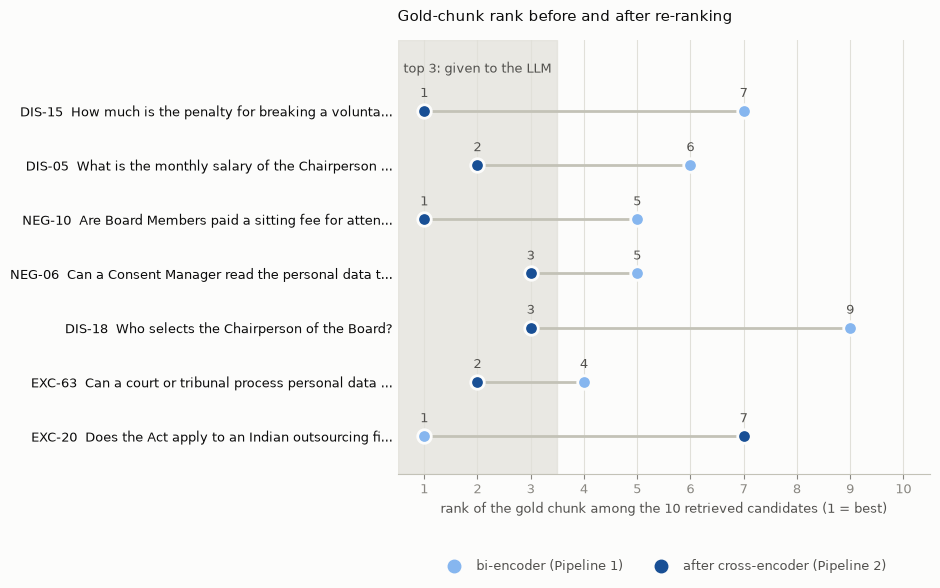

In [28]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Chart ink and surface colours; the two data colours are one blue hue in two shades (before = light, after = dark).
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BASELINE_COLOR, RERANKED_COLOR = "#86b6ef", "#184f95"


def plot_rank_shift(summary: pd.DataFrame, path: str = "results/rank_shift.png") -> None:
    """Dumbbell chart: where the gold chunk sat before (bi-encoder) and after (cross-encoder) re-ranking.

    Args:
        summary: The summary_df table (columns id, query, gold_rank_baseline, gold_rank_reranked).
        path: Where to save the PNG (kept in the repo for the report).
    """
    rows = list(summary.itertuples())[::-1]                               # first query at the top of the chart
    fig, ax = plt.subplots(figsize=(9.5, 0.62 * len(rows) + 1.7), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.axvspan(0.5, TOP_K_CONTEXT + 0.5, color=GRID, alpha=0.7, zorder=0)    # the zone the LLM actually sees
    ax.text(2, len(rows) - 0.35, "top 3: given to the LLM", ha="center", va="bottom", fontsize=9, color=INK_2)
    for y, r in enumerate(rows):
        ax.plot([r.gold_rank_baseline, r.gold_rank_reranked], [y, y], color=AXIS, lw=2, zorder=1, solid_capstyle="round")
        for rank, color in ((r.gold_rank_baseline, BASELINE_COLOR), (r.gold_rank_reranked, RERANKED_COLOR)):
            ax.scatter(rank, y, s=95, color=color, edgecolor=SURFACE, linewidth=2, zorder=3)   # surface ring keeps overlaps legible
            ax.annotate(str(rank), (rank, y), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"{r.id}  {r.query[:46]}{'...' if len(r.query) > 46 else ''}" for r in rows], fontsize=9, color=INK)
    ax.set_xlim(0.5, TOP_K_RETRIEVE + 0.5)
    ax.set_ylim(-0.7, len(rows) - 0.1 + 0.4)
    ax.set_xticks(range(1, TOP_K_RETRIEVE + 1))
    ax.tick_params(axis="x", colors=MUTED, labelsize=9)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("rank of the gold chunk among the 10 retrieved candidates (1 = best)", fontsize=9, color=INK_2)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.xaxis.grid(True, color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    handles = [Line2D([], [], marker="o", ls="", markersize=9, color=BASELINE_COLOR, label="bi-encoder (Pipeline 1)"),
               Line2D([], [], marker="o", ls="", markersize=9, color=RERANKED_COLOR, label="after cross-encoder (Pipeline 2)")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False, fontsize=9, labelcolor=INK_2)
    ax.set_title("Gold-chunk rank before and after re-ranking", loc="left", fontsize=11, color=INK, pad=14)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor=SURFACE)
    plt.show()


plot_rank_shift(summary_df)

## 9. Latency profiling

The retrieval pipeline is timed stage by stage, with `time.perf_counter`, over the six rescued queries of section 8, each repeated
30 times after a short warm-up (the first calls are slower while caches fill). Everything runs on CPU.

* **Pipeline 1 retrieval** = query embedding + FAISS search.
* **Pipeline 2 retrieval** = the same two stages + cross-encoder scoring of 10 pairs.

The Gemini call is an *external network call* with much larger and noisier latency, so it is reported separately
and is the same for both pipelines.

In [29]:
import platform

import torch

# Hardware context for the timings below.
cpuinfo = Path("/proc/cpuinfo")
cpu_model = next((line.split(":", 1)[1].strip() for line in cpuinfo.read_text().splitlines()
                  if line.startswith("model name")), "") if cpuinfo.exists() else ""
print(f"CPU: {cpu_model or platform.processor() or platform.machine()} | logical cores: {os.cpu_count()} | "
      f"torch threads: {torch.get_num_threads()} | torch {torch.__version__}")

CPU: AMD Ryzen 5 7520U with Radeon Graphics | logical cores: 8 | torch threads: 4 | torch 2.14.1+cpu


In [30]:
def profile_latency(queries: list[str], n_runs: int = 30, warmup: int = 3) -> pd.DataFrame:
    """Time every retrieval stage repeatedly and return per-run samples in milliseconds.

    Args:
        queries: Queries to time; each is run n_runs times.
        n_runs: Timed repetitions per query.
        warmup: Untimed repetitions of the first query to warm up the models.

    Returns:
        A DataFrame with one row per timed run and the columns embed_ms, search_ms, rerank_ms.
    """
    for _ in range(warmup):                              # untimed: lets lazy initialisation and caches settle
        hits, _t = retrieve(queries[0])
        rerank(queries[0], hits)
    rows = []
    for query in queries:
        for _ in range(n_runs):
            hits, t_ret = retrieve(query)
            _, t_rerank = rerank(query, hits)
            rows.append({"embed_ms": t_ret["embed_s"] * 1000, "search_ms": t_ret["search_s"] * 1000,
                         "rerank_ms": t_rerank * 1000})
    return pd.DataFrame(rows)


samples = profile_latency([CASES_BY_ID[c]["query"] for c in FAILURE_IDS])
samples["pipeline_1_ms"] = samples["embed_ms"] + samples["search_ms"]          # baseline retrieval
samples["pipeline_2_ms"] = samples["pipeline_1_ms"] + samples["rerank_ms"]     # retrieval + re-ranking

stage_labels = {"embed_ms": "query embedding (bi-encoder)", "search_ms": "FAISS search (top 10)",
                "pipeline_1_ms": "PIPELINE 1 retrieval total", "rerank_ms": "cross-encoder, 10 pairs",
                "pipeline_2_ms": "PIPELINE 2 retrieval total"}
latency_df = pd.DataFrame({
    label: {"mean_ms": samples[col].mean(), "median_ms": samples[col].median(), "p95_ms": samples[col].quantile(0.95)}
    for col, label in stage_labels.items()
}).T.round(2)
print(f"{len(samples)} timed runs")
latency_df

180 timed runs


,mean_ms,median_ms,p95_ms
query embedding (bi-encoder),12.61,12.50,14.26
FAISS search (top 10),0.08,0.07,0.12
PIPELINE 1 retrieval total,12.69,12.58,14.40
"cross-encoder, 10 pairs",362.71,361.46,384.00
PIPELINE 2 retrieval total,375.41,374.40,395.89


In [31]:
# LLM latency (one call per answer; network + generation, same model and prompt for both pipelines).
llm_df = pd.DataFrame({
    "answer_1_s": [r.answer_1["seconds"] for r in final_results.values()],
    "answer_2_s": [r.answer_2["seconds"] for r in final_results.values()],
}, index=list(final_results)).round(2)
llm_df.loc["median"] = llm_df.median().round(2)
llm_df

,answer_1_s,answer_2_s
DIS-15,8.36,4.07
DIS-05,3.30,2.51
NEG-10,8.28,8.19
NEG-06,2.81,5.47
DIS-18,6.29,1.88
EXC-63,122.58,86.33
EXC-20,125.33,28.68
median,8.28,5.47


In [32]:
# End-to-end view: median retrieval time from the profile above plus ONE pooled median Gemini call time. Both pipelines
# use the same model and prompt template, and a single call varies by seconds with network and server load, so the
# pooled median of all saved calls is used for both rows: the difference between the rows is then retrieval only.
llm_pooled_ms = statistics.median(a["seconds"] for r in final_results.values() for a in (r.answer_1, r.answer_2)) * 1000
end_to_end_df = pd.DataFrame({
    "retrieval_ms": [latency_df.loc["PIPELINE 1 retrieval total", "median_ms"],
                     latency_df.loc["PIPELINE 2 retrieval total", "median_ms"]],
    "gemini_call_ms": [llm_pooled_ms, llm_pooled_ms],
}, index=["Pipeline 1", "Pipeline 2"])
end_to_end_df["end_to_end_ms"] = end_to_end_df.sum(axis=1)
end_to_end_df.round(0)

,retrieval_ms,gemini_call_ms,end_to_end_ms
Pipeline 1,13.0,7239.0,7251.0
Pipeline 2,374.0,7239.0,7613.0


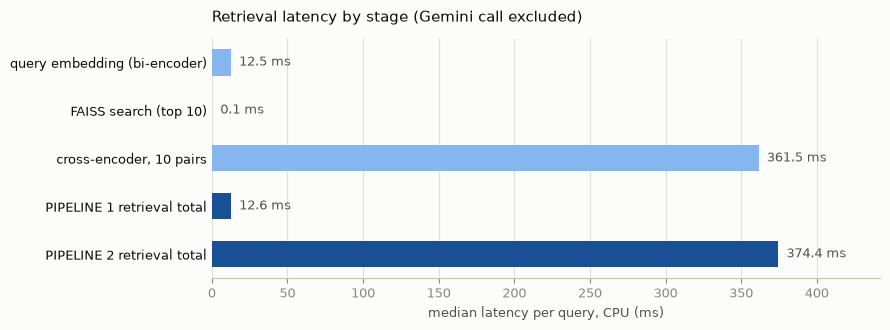

In [33]:
def plot_latency(table: pd.DataFrame, path: str = "results/latency.png") -> None:
    """Horizontal bars of the median latency per retrieval stage (light = single stage, dark = pipeline total).

    Args:
        table: The latency_df table (index = stage label, column median_ms).
        path: Where to save the PNG (kept in the repo for the report).
    """
    order = ["query embedding (bi-encoder)", "FAISS search (top 10)", "cross-encoder, 10 pairs",
             "PIPELINE 1 retrieval total", "PIPELINE 2 retrieval total"]
    medians = table.loc[order, "median_ms"][::-1]                            # reversed so the first stage is on top
    colors = [RERANKED_COLOR if "PIPELINE" in label else BASELINE_COLOR for label in medians.index]
    fig, ax = plt.subplots(figsize=(9, 3.4), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.barh(medians.index, medians.values, color=colors, height=0.55)
    for y, value in enumerate(medians.values):                               # direct value labels on every bar
        ax.annotate(f"{value:.1f} ms", (value, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
    ax.set_xlim(0, medians.max() * 1.18)
    ax.tick_params(axis="y", length=0, labelsize=9, labelcolor=INK)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9)
    ax.set_xlabel("median latency per query, CPU (ms)", fontsize=9, color=INK_2)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_title("Retrieval latency by stage (Gemini call excluded)", loc="left", fontsize=11, color=INK, pad=12)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor=SURFACE)
    plt.show()


plot_latency(latency_df)

## 10. Why not run the cross-encoder over the whole corpus?

A quick measurement: score **every** chunk of this (tiny) corpus with the cross-encoder, compare its per-pair cost
with the bi-encoder's search time, and extrapolate to larger collections.

In [34]:
query = CASES_BY_ID["DIS-05"]["query"]

# Cross-encoder over ALL chunks: one forward pass per (query, chunk) pair.
t0 = time.perf_counter()
cross_encoder.predict([(query, c.text) for c in chunks], batch_size=32, show_progress_bar=False)
all_pairs_s = time.perf_counter() - t0
per_pair_ms = all_pairs_s / len(chunks) * 1000
print(f"Cross-encoder on all {len(chunks)} chunks: {all_pairs_s:.2f} s  ({per_pair_ms:.1f} ms per pair)")
ce_10_median_ms = latency_df.loc['cross-encoder, 10 pairs', 'median_ms']
print(f"Cross-encoder on the 10 re-ranked candidates (median of the runs above): {ce_10_median_ms:.0f} ms")
measured_rows = [
    {"measurement": f"cross-encoder, all {len(chunks)} chunks (s)", "value": round(all_pairs_s, 2)},
    {"measurement": "cross-encoder, per (query, chunk) pair (ms)", "value": round(per_pair_ms, 1)},
    {"measurement": "cross-encoder, the 10 re-ranked candidates, median (ms)", "value": round(ce_10_median_ms, 1)},
]

# Bi-encoder side: exact FAISS search over random unit vectors of the same dimension, to see how it grows.
rng = np.random.default_rng(0)
dim = chunk_vectors.shape[1]
search_rows = []
for n_vectors in (10_000, 100_000):
    big = faiss.IndexFlatIP(dim)
    vectors = rng.standard_normal((n_vectors, dim)).astype("float32")
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
    big.add(vectors)
    q = vectors[:1]
    big.search(q, 10)                                        # warm-up
    t0 = time.perf_counter()
    for _ in range(20):
        big.search(q, 10)
    search_rows.append({"collection_size": n_vectors, "faiss_flat_search_ms": (time.perf_counter() - t0) / 20 * 1000})
    measured_rows.append({"measurement": f"FAISS flat search over {n_vectors:,} vectors (ms)",
                          "value": round(search_rows[-1]["faiss_flat_search_ms"], 2)})
    del big, vectors
display(pd.DataFrame(search_rows).round(2))

# Extrapolation: the cross-encoder cost per query grows linearly with the number of chunks.
extrapolation = pd.DataFrame({
    "chunks_in_collection": [len(chunks), 10_000, 100_000, 1_000_000],
}).assign(cross_encoder_all_pairs_seconds=lambda d: d["chunks_in_collection"] * per_pair_ms / 1000)
extrapolation.round(1)

Cross-encoder on all 230 chunks: 9.75 s  (42.4 ms per pair)
Cross-encoder on the 10 re-ranked candidates (median of the runs above): 361 ms


,collection_size,faiss_flat_search_ms
0,10000,1.78
1,100000,17.57


,chunks_in_collection,cross_encoder_all_pairs_seconds
0,230,9.8
1,10000,424.0
2,100000,4240.4
3,1000000,42403.5


In [35]:
# Save the numbers used in the report next to the notebook (small, text-only files).
import json

records = []
for cid, cmp in final_results.items():
    case = CASES_BY_ID[cid]
    records.append({
        "id": cid, "category": case["category"], "query": case["query"], "gold_chunks": sorted(case["gold"]),
        "baseline_rank": best_rank([h.chunk_id for h in cmp.baseline_hits], case["gold"]),
        "reranked_rank": best_rank([h.chunk_id for h in cmp.reranked_hits], case["gold"]),
        "context_answer_1": cmp.context_1, "context_answer_2": cmp.context_2,
        "reference_answer": REFERENCE_ANSWERS[cid],
        "answer_1": cmp.answer_1["text"], "answer_2": cmp.answer_2["text"],
        "answer_1_check": judge_answer(cid, cmp.answer_1["text"]),
        "answer_2_check": judge_answer(cid, cmp.answer_2["text"]),
    })
Path("results/final_comparisons.json").write_text(json.dumps(records, indent=2, ensure_ascii=False))
latency_df.to_csv("results/latency_profile.csv")
aggregate_df.rename_axis("pipeline").reset_index().to_csv("results/aggregate_metrics.csv", index=False)
end_to_end_df.round(0).rename_axis("pipeline").to_csv("results/end_to_end_latency.csv")
extrapolation.round(1).to_csv("results/scaling_extrapolation.csv", index=False)
pd.DataFrame(measured_rows).to_csv("results/scaling_measured.csv", index=False)
print("Saved the tables and records used in the report to results/")

Saved the tables and records used in the report to results/
